# Signal 3 default model

We are Lender 3: for new applicants we see the shared features plus our own `signal3`. This notebook tunes and compares default models on the shared train split, scores them once on the test split, refits the selected model on all past loans and predicts the default probability (PD) of the new applications.

- `sex` is not used as a feature.
- `signal1` and `signal2` are not used: new applicants only have `signal3`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import sklearn
import xgboost as xgb
from catboost import CatBoostClassifier, Pool
from catboost import cv as catboost_cv
from catboost import __version__ as catboost_version
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import SplineTransformer, StandardScaler

SEED = 42
RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")
COLORS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]  # Okabe-Ito, colorblind-safe

TARGET = "default"

# Same 5 CV folds on train for every model; the test split is never used for tuning
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"Seed: {SEED} | scikit-learn {sklearn.__version__}, xgboost {xgb.__version__}, "
      f"catboost {catboost_version}, optuna {optuna.__version__}")

Seed: 42 | scikit-learn 1.6.1, xgboost 3.1.2, catboost 1.2.8, optuna 4.5.0


## 1. Load the shared split and the new applications

In [2]:
train = pd.read_csv(PROCESSED_DIR / "train.csv")
test = pd.read_csv(PROCESSED_DIR / "test.csv")
new = pd.read_csv(RAW_DIR / "NewApplications_Lender3_Round1.csv")

for name, part in [("train", train), ("test", test)]:
    print(f"{name}: {len(part):,} rows, default rate {part[TARGET].mean():.2%}")
print(f"new applications: {len(new):,} rows")

# Check the files come from the shared split
assert (len(train), len(test)) == (70_000, 30_000), "unexpected split sizes: re-run eda_and_split.ipynb"
assert not set(train["id"]) & set(test["id"]), "a borrower appears in both train and test"
assert new["id"].is_unique and not new.isna().any().any(), "new applications: duplicate ids or missing values"

train: 70,000 rows, default rate 9.95%
test: 30,000 rows, default rate 9.95%
new applications: 100,000 rows


## 2. Features

These transforms work row by row and learn nothing from the data, so they are applied once, identically, to train, test and the new applications:

- `employment` one-hot encoded: the linear models drop `employed` as the reference level (the four dummies would duplicate the intercept), XGBoost gets all four so a single split can separate any one group, and CatBoost uses the raw column as a category
- `log_income = log(1 + income)`, since income is right-skewed and top-coded at 1M €, plus a `zero_income` flag (~17% of loans, with a much higher default rate)
- a `signal3_zero` flag, since ~20% of `signal3` is exactly 0 (a mass point)

Transforms that learn from the data (scaling, spline knots) sit inside each model's pipeline, so they are fit on the training folds only.

In [3]:
EMPLOYMENT_LEVELS = ["employed", "retired", "student", "unemployed"]
EMPLOYMENT_ALL = [f"employment_{level}" for level in EMPLOYMENT_LEVELS]
EMPLOYMENT_DUMMIES = EMPLOYMENT_ALL[1:]  # linear models: "employed" is the reference level


def prepare(df: pd.DataFrame) -> pd.DataFrame:
    """Model features of a loans or applications table (row-wise, nothing fitted)."""
    unknown = set(df["employment"]) - set(EMPLOYMENT_LEVELS)
    assert not unknown, f"unknown employment levels: {unknown}"
    X = pd.DataFrame(index=df.index)
    X["employment"] = df["employment"]
    for level, col in zip(EMPLOYMENT_LEVELS, EMPLOYMENT_ALL):
        X[col] = (df["employment"] == level).astype(int)
    X["married"] = df["married"]
    X["income"] = df["income"]
    X["log_income"] = np.log1p(df["income"])
    X["zero_income"] = (df["income"] == 0).astype(int)
    X["signal3"] = df["signal3"]
    X["signal3_zero"] = (df["signal3"] == 0).astype(int)
    return X


# Feature sets per model family
BINARY = EMPLOYMENT_DUMMIES + ["married", "zero_income", "signal3_zero"]
CONTINUOUS = ["log_income", "signal3"]                   # scaled (logreg) or splined (spline logreg)
TREE_FEATURES = EMPLOYMENT_ALL + ["married", "income", "signal3"]  # trees split on raw values; log and zero flags add nothing
CATBOOST_FEATURES = ["employment", "married", "income", "signal3"]
CATBOOST_CATEGORICAL = ["employment"]

X_train, y_train = prepare(train), train[TARGET]
X_test, y_test = prepare(test), test[TARGET]
X_new = prepare(new)
folds = list(CV.split(X_train, y_train))  # explicit folds, shared by xgb.cv and catboost.cv

X_train.head()

,employment,employment_employed,employment_retired,employment_student,employment_unemployed,married,income,log_income,zero_income,signal3,signal3_zero
0,employed,1,0,0,0,1,15064,9.620129,0,0.579146,0
1,employed,1,0,0,0,0,6816,8.827175,0,0.486127,0
2,student,0,0,1,0,0,0,0.000000,1,0.862158,0
3,employed,1,0,0,0,1,28404,10.254320,0,0.193084,0
4,employed,1,0,0,0,0,7030,8.858084,0,0.000000,1


## 3. Evaluation and baseline

In [4]:
def evaluate(y_true: np.ndarray, p_pred: np.ndarray) -> dict[str, float]:
    """Log loss, Brier score and AUC of predicted default probabilities."""
    return {
        "log_loss": log_loss(y_true, p_pred),
        "brier": brier_score_loss(y_true, p_pred),
        "auc": roc_auc_score(y_true, p_pred),
    }


def plot_calibration(
    y_true: np.ndarray, probs: dict[str, np.ndarray], title: str = "Calibration on the test split", n_bins: int = 10
) -> None:
    """Plot observed default rate vs mean predicted probability per quantile bin."""
    _, ax = plt.subplots(figsize=(5.5, 5))
    top = 0.0
    for (name, p), color in zip(probs.items(), COLORS):
        observed, predicted = calibration_curve(y_true, p, n_bins=n_bins, strategy="quantile")
        ax.plot(predicted * 100, observed * 100, marker="o", color=color, label=name)
        top = max(top, predicted.max(), observed.max())
    ax.plot([0, top * 100], [0, top * 100], ls="--", lw=1, color="black", label="Perfect calibration")
    ax.set(title=title, xlabel="Mean predicted default probability (%)",
           ylabel="Observed default rate (%)")
    ax.legend()
    plt.show()


def calibration_slope(y_true: np.ndarray, p_pred: np.ndarray) -> tuple[float, float]:
    """Calibration slope and intercept from refitting y on logit(p)."""
    p = np.clip(p_pred, 1e-6, 1 - 1e-6)
    logit = np.log(p / (1 - p)).reshape(-1, 1)
    fit = LogisticRegression(C=np.inf).fit(logit, y_true)
    return fit.coef_[0][0], fit.intercept_[0]


def sklearn_fitter(estimator):
    """Fit function for a tuned sklearn estimator: refits a copy and returns its PD predictor."""
    def fit(X: pd.DataFrame, y: pd.Series):
        model = clone(estimator).fit(X, y)
        return lambda Z: model.predict_proba(Z)[:, 1]
    return fit


def oof_predictions(fit, X: pd.DataFrame, y: pd.Series) -> np.ndarray:
    """Out-of-fold PDs on train: fit on 4 folds, predict the 5th."""
    oof = np.zeros(len(y))
    for fit_idx, val_idx in folds:
        predict = fit(X.iloc[fit_idx], y.iloc[fit_idx])
        oof[val_idx] = predict(X.iloc[val_idx])
    return oof


def record(name: str, cv_scores: tuple[float, float], p_test: np.ndarray) -> None:
    """Store CV log loss (mean, std) and test scores of a model."""
    test_probs[name] = p_test
    results[name] = {"cv_log_loss": cv_scores[0], "cv_std": cv_scores[1], **evaluate(y_test, p_test)}


results = {}
test_probs = {}
fitters = {}  # model name -> fit(X, y) returning a PD predictor, with the tuned settings (used for the final refit)

dummy = DummyClassifier(strategy="prior")
dummy_cv = -cross_val_score(dummy, X_train[TREE_FEATURES], y_train, cv=CV, scoring="neg_log_loss")
record("dummy (prior)", (dummy_cv.mean(), dummy_cv.std()), dummy.fit(X_train[TREE_FEATURES], y_train).predict_proba(X_test[TREE_FEATURES])[:, 1])

pd.DataFrame(results).T.round(4)

,cv_log_loss,cv_std,log_loss,brier,auc
dummy (prior),0.3239,0.0001,0.3239,0.0896,0.5


## 4. Logistic regression

Continuous features are standardised inside the pipeline; the regularisation strength `C` is tuned by grid search on 5-fold CV log loss.

In [5]:
logreg_pipe = Pipeline([
    ("prep", ColumnTransformer([
        ("num", StandardScaler(), CONTINUOUS),
        ("bin", "passthrough", BINARY),
    ])),
    ("model", LogisticRegression(max_iter=1000)),
])
logreg_search = GridSearchCV(
    logreg_pipe, {"model__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000]}, cv=CV, scoring="neg_log_loss"
).fit(X_train, y_train)

best = logreg_search.best_index_
record("logreg", (-logreg_search.best_score_, logreg_search.cv_results_["std_test_score"][best]),
       logreg_search.predict_proba(X_test)[:, 1])
fitters["logreg"] = sklearn_fitter(logreg_search.best_estimator_)
print(f"Best C: {logreg_search.best_params_['model__C']}")

# Coefficients on standardised continuous features, so their sizes are comparable
coefs = logreg_search.best_estimator_["model"].coef_[0]
pd.Series(coefs, index=CONTINUOUS + BINARY, name="coefficient").round(3)

Best C: 1000


log_income              -4.156
signal3                 -0.432
employment_retired      -0.956
employment_student      -0.626
employment_unemployed   -0.245
married                 -0.087
zero_income             -9.049
signal3_zero            -0.641
Name: coefficient, dtype: float64

## 5. Spline logistic regression

Cubic splines on `signal3` and `log_income` let the default rate bend instead of following one straight line on the logit scale. A spline cannot jump at exactly 0, so the `signal3_zero` and `zero_income` flags stay in. Number of knots and `C` are tuned by grid search on CV log loss.

In [6]:
spline_pipe = Pipeline([
    ("prep", ColumnTransformer([
        ("spline", SplineTransformer(degree=3, knots="quantile"), CONTINUOUS),
        ("bin", "passthrough", BINARY),
    ])),
    ("model", LogisticRegression(max_iter=2000)),
])
spline_grid = {"prep__spline__n_knots": [4, 6, 8, 10, 12], "model__C": [0.1, 1, 10, 100, 1000, 10000]}
spline_search = GridSearchCV(spline_pipe, spline_grid, cv=CV, scoring="neg_log_loss").fit(X_train, y_train)

best = spline_search.best_index_
record("spline logreg", (-spline_search.best_score_, spline_search.cv_results_["std_test_score"][best]),
       spline_search.predict_proba(X_test)[:, 1])
fitters["spline logreg"] = sklearn_fitter(spline_search.best_estimator_)
print(f"Best settings: {spline_search.best_params_}")

pd.DataFrame(results).T.round(4)

Best settings: {'model__C': 100, 'prep__spline__n_knots': 4}


,cv_log_loss,cv_std,log_loss,brier,auc
dummy (prior),0.3239,0.0001,0.3239,0.0896,0.5000
logreg,0.2924,0.0015,0.2920,0.0840,0.7347
spline logreg,0.2906,0.0016,0.2906,0.0835,0.7363


## 6. XGBoost

Optuna tunes the hyperparameters on the same 5-fold CV log loss; early stopping sets the number of trees.

In [7]:
dtrain = xgb.DMatrix(X_train[TREE_FEATURES], label=y_train)
XGB_BASE = {"objective": "binary:logistic", "eval_metric": "logloss", "tree_method": "hist", "seed": SEED}
N_TRIALS = 40


def xgb_objective(trial: optuna.Trial) -> float:
    params = XGB_BASE | {
        "eta": trial.suggest_float("eta", 0.01, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 200, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "lambda": trial.suggest_float("lambda", 1e-3, 10, log=True),
        "gamma": trial.suggest_float("gamma", 1e-4, 5, log=True),
    }
    cv = xgb.cv(params, dtrain, num_boost_round=2000, folds=folds, early_stopping_rounds=50, verbose_eval=False)
    trial.set_user_attr("n_rounds", len(cv))
    trial.set_user_attr("cv_std", cv["test-logloss-std"].iloc[-1])
    return cv["test-logloss-mean"].iloc[-1]


optuna.logging.set_verbosity(optuna.logging.WARNING)
xgb_study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
xgb_study.optimize(xgb_objective, n_trials=N_TRIALS)

xgb_params = XGB_BASE | xgb_study.best_params
xgb_rounds = xgb_study.best_trial.user_attrs["n_rounds"]
print(f"Best CV log loss {xgb_study.best_value:.4f} with {xgb_rounds} trees: {xgb_study.best_params}")


def fit_xgb(X: pd.DataFrame, y: pd.Series):
    """Train XGBoost with the tuned settings; returns its PD predictor."""
    booster = xgb.train(xgb_params, xgb.DMatrix(X[TREE_FEATURES], label=y), num_boost_round=xgb_rounds)
    return lambda Z: booster.predict(xgb.DMatrix(Z[TREE_FEATURES]))


fitters["xgboost"] = fit_xgb

Best CV log loss 0.2906 with 525 trees: {'eta': 0.014124738109773749, 'max_depth': 3, 'min_child_weight': 1.632956189955042, 'subsample': 0.5056601521163473, 'colsample_bytree': 0.8469322067804477, 'lambda': 0.012223769717152288, 'gamma': 0.7757959394658933}


## 7. CatBoost

CatBoost uses `employment` as a categorical feature directly (no one-hot). Optuna tunes it on the same folds and CV log loss; early stopping sets the number of trees.

In [8]:
train_pool = Pool(X_train[CATBOOST_FEATURES], label=y_train, cat_features=CATBOOST_CATEGORICAL)
CB_BASE = {"loss_function": "Logloss", "bootstrap_type": "Bernoulli", "random_seed": SEED,
           "logging_level": "Silent", "allow_writing_files": False}


def catboost_objective(trial: optuna.Trial) -> float:
    params = CB_BASE | {
        "iterations": 2000,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "depth": trial.suggest_int("depth", 2, 8),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1e-2, 30, log=True),
        "random_strength": trial.suggest_float("random_strength", 1e-3, 10, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
    }
    cv = catboost_cv(train_pool, params, folds=folds, early_stopping_rounds=50)
    best_iter = cv["test-Logloss-mean"].idxmin()
    trial.set_user_attr("n_rounds", int(cv.loc[best_iter, "iterations"]) + 1)
    trial.set_user_attr("cv_std", cv.loc[best_iter, "test-Logloss-std"])
    return cv.loc[best_iter, "test-Logloss-mean"]


cb_study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
cb_study.optimize(catboost_objective, n_trials=N_TRIALS)

cb_params = CB_BASE | cb_study.best_params
cb_rounds = cb_study.best_trial.user_attrs["n_rounds"]
print(f"Best CV log loss {cb_study.best_value:.4f} with {cb_rounds} trees: {cb_study.best_params}")


def fit_catboost(X: pd.DataFrame, y: pd.Series):
    """Train CatBoost with the tuned settings; returns its PD predictor."""
    model = CatBoostClassifier(**cb_params, iterations=cb_rounds)
    model.fit(X[CATBOOST_FEATURES], y, cat_features=CATBOOST_CATEGORICAL)
    return lambda Z: model.predict_proba(Z[CATBOOST_FEATURES])[:, 1]


fitters["catboost"] = fit_catboost

Best CV log loss 0.2905 with 815 trees: {'learning_rate': 0.019569339694509677, 'depth': 6, 'l2_leaf_reg': 0.20731539095919654, 'random_strength': 2.2014350576563353, 'subsample': 0.9150555458590272}


### Calibration of the boosted models, out-of-fold on train

Done on train only: if the points sit on the diagonal (slope ≈ 1, intercept ≈ 0), no recalibration step is needed.

xgboost: out-of-fold log loss 0.2906 | mean predicted 9.95% vs observed 9.95% | calibration slope 1.026, intercept 0.050
catboost: out-of-fold log loss 0.2906 | mean predicted 9.95% vs observed 9.95% | calibration slope 0.997, intercept -0.006


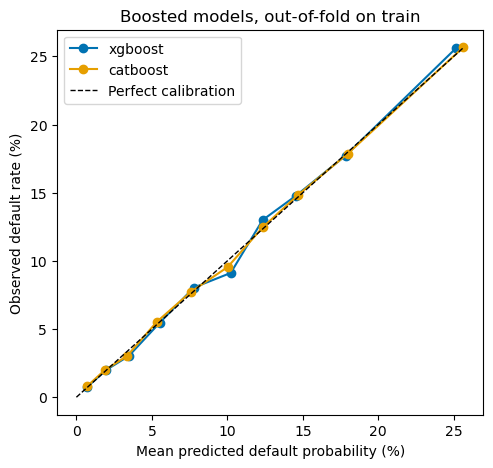

In [9]:
oof = {name: oof_predictions(fitters[name], X_train, y_train) for name in ["xgboost", "catboost"]}
for name, p in oof.items():
    slope, intercept = calibration_slope(y_train, p)
    print(f"{name}: out-of-fold log loss {log_loss(y_train, p):.4f} | mean predicted {p.mean():.2%} "
          f"vs observed {y_train.mean():.2%} | calibration slope {slope:.3f}, intercept {intercept:.3f}")
plot_calibration(y_train, oof, title="Boosted models, out-of-fold on train")

### Final boosted fits on train and test scores

In [10]:
record("xgboost", (xgb_study.best_value, xgb_study.best_trial.user_attrs["cv_std"]),
       fit_xgb(X_train, y_train)(X_test))
record("catboost", (cb_study.best_value, cb_study.best_trial.user_attrs["cv_std"]),
       fit_catboost(X_train, y_train)(X_test))

pd.DataFrame(results).T.round(4)

,cv_log_loss,cv_std,log_loss,brier,auc
dummy (prior),0.3239,0.0001,0.3239,0.0896,0.5000
logreg,0.2924,0.0015,0.2920,0.0840,0.7347
spline logreg,0.2906,0.0016,0.2906,0.0835,0.7363
xgboost,0.2906,0.0016,0.2905,0.0836,0.7368
catboost,0.2905,0.0018,0.2904,0.0835,0.7367


## 8. Compare on the test split

In [11]:
comparison = pd.DataFrame(results).T.sort_values("cv_log_loss")
comparison.round(4)

,cv_log_loss,cv_std,log_loss,brier,auc
catboost,0.2905,0.0018,0.2904,0.0835,0.7367
xgboost,0.2906,0.0016,0.2905,0.0836,0.7368
spline logreg,0.2906,0.0016,0.2906,0.0835,0.7363
logreg,0.2924,0.0015,0.2920,0.0840,0.7347
dummy (prior),0.3239,0.0001,0.3239,0.0896,0.5000


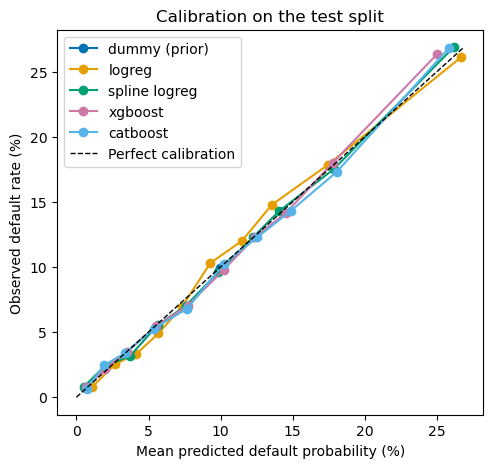

In [12]:
plot_calibration(y_test, test_probs)

### Learned effect of signal 3

Mean predicted PD vs observed default rate per `signal3` bin on the test split (same bins as the EDA: exactly 0, then deciles of the positive values).

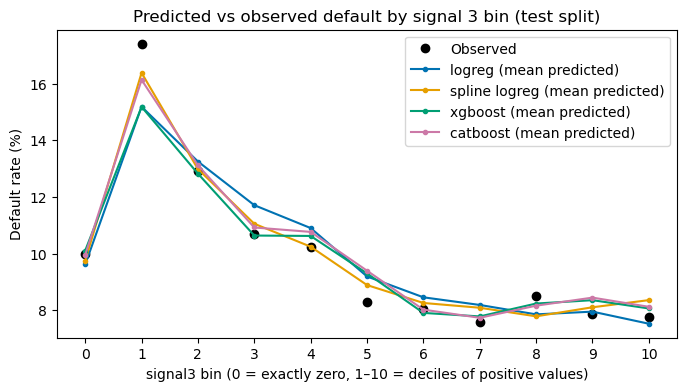

In [13]:
positive = X_test["signal3"] > 0
signal_bin = pd.Series(0, index=X_test.index)
signal_bin[positive] = pd.qcut(X_test.loc[positive, "signal3"], 10, labels=False) + 1
models = [name for name in test_probs if name != "dummy (prior)"]
by_bin = pd.DataFrame({"observed": y_test, **{name: test_probs[name] for name in models}},
                      index=X_test.index).groupby(signal_bin).mean() * 100

_, ax = plt.subplots(figsize=(8, 4))
ax.plot(by_bin.index, by_bin["observed"], "o", color="black", label="Observed")
for name, color in zip(models, COLORS):
    ax.plot(by_bin.index, by_bin[name], marker=".", color=color, label=f"{name} (mean predicted)")
ax.set(title="Predicted vs observed default by signal 3 bin (test split)",
       xlabel="signal3 bin (0 = exactly zero, 1–10 = deciles of positive values)", ylabel="Default rate (%)",
       xticks=range(11))
ax.legend()
plt.show()

## 9. Select, refit and export

The model with the lowest CV log loss is selected; its test score above is the performance estimate. It is then refit with the same settings (no re-tuning) on all 100,000 past loans (train + test) to predict the new applications.

All prediction files use the agreed format `id, pd, pred, threshold`; the 0.5 threshold is for the format only, pricing uses `pd`.

In [14]:
selected = comparison.index[0]
assert selected != "dummy (prior)", "no model beats the prior"
TAGS = {"logreg": "logreg", "spline logreg": "spline", "xgboost": "xgboost", "catboost": "catboost"}
tag = TAGS[selected]
THRESHOLD = 0.5
print(f"Selected model: {selected}")


def prediction_table(ids: pd.Series, p: np.ndarray) -> pd.DataFrame:
    return pd.DataFrame({"id": ids.to_numpy(), "pd": p, "pred": (p >= THRESHOLD).astype(int), "threshold": THRESHOLD})


# Test split predictions of the selected model, trained on train only
test_predictions = prediction_table(test["id"], test_probs[selected])
test_predictions.to_csv(PROCESSED_DIR / f"signal3_test_predictions_{tag}.csv", index=False)

# Refit on all past loans, then predict the new applications
past = pd.concat([train, test], ignore_index=True)
predict_new = fitters[selected](prepare(past), past[TARGET])
new_predictions = prediction_table(new["id"], predict_new(X_new))

assert len(new_predictions) == len(new) and new_predictions["pd"].between(0, 1).all()
new_path = PROCESSED_DIR / f"signal3_new_applications_predictions_{tag}.csv"
new_predictions.to_csv(new_path, index=False)

# Same population, so the mean PD should be close to the past default rate
print(f"{new_path.name}: {len(new_predictions):,} rows | mean PD {new_predictions['pd'].mean():.2%} "
      f"vs past default rate {past[TARGET].mean():.2%}")
new_predictions["pd"].describe().round(4)

Selected model: catboost
signal3_new_applications_predictions_catboost.csv: 100,000 rows | mean PD 9.93% vs past default rate 9.95%


count    100000.0000
mean          0.0993
std           0.0769
min           0.0001
25%           0.0343
50%           0.0867
75%           0.1461
max           0.4886
Name: pd, dtype: float64

In [15]:
comparison.round(4).to_csv(PROCESSED_DIR / "signal3_metrics.csv", index_label="model")

best_settings = {
    "selected": selected,
    "logreg": logreg_search.best_params_,
    "spline logreg": spline_search.best_params_,
    "xgboost": {**xgb_study.best_params, "n_rounds": xgb_rounds},
    "catboost": {**cb_study.best_params, "n_rounds": cb_rounds},
}
(PROCESSED_DIR / "signal3_best_params.json").write_text(json.dumps(best_settings, indent=2))
print("Saved signal3_metrics.csv and signal3_best_params.json")

Saved signal3_metrics.csv and signal3_best_params.json
